# P5 : test final sur H2 et Grad-CAM

**Avant de commencer :** crée un dossier `P5` à la racine de ton Google Drive et mets-y `best_model.pth` et `predictions_resnet.csv`.

**Ordre :** 0. Charger les données avec `01_charger_donnees.ipynb` → 1. Charger le modèle → 2. **Contrôle sur H1** → 3. Seuil figé → 4. **Test H2 (une seule fois)** → 5. Erreurs par lame → 6. Grad-CAM.

Règle : on n'exécute l'étape 4 qu'une seule fois, et seulement si le contrôle de l'étape 2 est validé. Aucun réglage ne doit être fait après avoir vu les résultats de H2.

## 0. Données
On utilise la même fonction que le reste de l'équipe (`charger_donnees` de P1, dans le dépôt). Elle lit le parquet, ajoute `split_equipe` et vérifie qu'il n'y a pas de fuite.

In [2]:
import os, sys
from google.colab import drive
drive.mount('/content/drive')
if not os.path.exists('depot'):
    !git clone --depth 1 https://github.com/kenzo-kouokam/detection-metastases-camelyon17.git depot
sys.path.insert(0, 'depot/p1_data')
from charger_donnees import charger_donnees

DOSSIER = '/content/drive/MyDrive/P5/resultats'   # dans TON Drive (SPE1 est en lecture seule)
os.makedirs(DOSSIER, exist_ok=True)

df = charger_donnees()
print(df.shape)
print(df.columns.tolist())
print(df['split_equipe'].value_counts())

Mounted at /content/drive
Cloning into 'depot'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 34 (delta 1), reused 19 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (34/34), 4.00 MiB | 20.57 MiB/s, done.
Resolving deltas: 100% (1/1), done.
(39000, 11)
['image', 'label', 'center', 'image_id', 'patient', 'node', 'x_coord', 'y_coord', 'slide', 'split', 'split_equipe']
split_equipe
train_interne    19483
test              8000
val_interne       7517
val_ood           4000
Name: count, dtype: int64


## 1. Modèle

In [3]:
import torch, torch.nn as nn, torchvision, numpy as np, pandas as pd, io
from PIL import Image
from sklearn.metrics import roc_auc_score
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Appareil :', device)

CHEMIN_MODELE = '/content/drive/MyDrive/SPE1/best_model.pth'

model = torchvision.models.resnet18(weights=None)
model.fc = nn.Sequential(nn.Linear(512, 128), nn.ReLU(), nn.Dropout(0.5), nn.Linear(128, 2))
etat = torch.load(CHEMIN_MODELE, map_location=device)
model.load_state_dict(etat)
model = model.to(device).eval()
print('Modèle chargé')

Appareil : cuda
Modèle chargé


### Prétraitement
Identique à celui de P3 : `get_transforms('colorjitter')` de P1, version **évaluation** (ToTensor + normalisation ImageNet, sans augmentation), comme dans `02_resnet.ipynb`.

In [4]:
from preprocessing import get_transforms
_, TRANSFORM = get_transforms('colorjitter')   # même mode que P3 (MODE_TRANSFORM dans 02_resnet.ipynb)
print(TRANSFORM)

COL_IMG = 'image'   # colonne des octets PNG, comme dans le notebook de P2

def vers_pil(x):
    if isinstance(x, dict): x = x.get('bytes', x)
    if isinstance(x, (bytes, bytearray)): return Image.open(io.BytesIO(x)).convert('RGB')
    if isinstance(x, Image.Image): return x.convert('RGB')
    return Image.fromarray(np.asarray(x, dtype=np.uint8)).convert('RGB')

@torch.no_grad()
def predire(sous_df, taille_lot=256):
    probas = []
    for i in range(0, len(sous_df), taille_lot):
        lot = torch.stack([TRANSFORM(vers_pil(x)) for x in sous_df[COL_IMG].iloc[i:i+taille_lot]]).to(device)
        probas.append(torch.softmax(model(lot), 1)[:, 1].cpu().numpy())
    return np.concatenate(probas)

Compose(
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 2. Contrôle sur H1 (obligatoire avant H2)
On recalcule les prédictions sur `val_ood` (H1) et on les compare à `predictions_resnet.csv` de P3. On attend une **AUC ≈ 0,959** et des probabilités presque identiques.

In [5]:
h1 = df[df['split_equipe'] == 'val_ood'].copy()
h1['proba'] = predire(h1)
auc_h1 = roc_auc_score(h1['label'], h1['proba'])
print(f'AUC H1 recalculée : {auc_h1:.3f}   (attendu : 0,959)')

try:
    ref = pd.read_csv('/content/drive/MyDrive/SPE1/predictions_resnet.csv')
    comp = h1.merge(ref[['image_id', 'proba']], on='image_id', suffixes=('', '_p3'))
    ecart = (comp['proba'] - comp['proba_p3']).abs().max()
    print(f'Écart maximal avec P3 sur {len(comp)} patchs : {ecart:.4f}')
except Exception as e:
    print('Comparaison avec P3 impossible :', e)

CONTROLE_OK = abs(auc_h1 - 0.959) < 0.005
print('CONTRÔLE VALIDÉ' if CONTROLE_OK else 'ARRÊT : le prétraitement ne correspond pas à celui de P3. Ne pas lancer H2.')

AUC H1 recalculée : 0.959   (attendu : 0,959)
Écart maximal avec P3 sur 4000 patchs : 0.0000
CONTRÔLE VALIDÉ


## 3. Seuil figé sur H1
Le seuil est choisi **sur H1 uniquement** pour obtenir **au moins 90 % de rappel**. Attendu : environ 0,356.

In [6]:
RAPPEL_VISE = 0.90
pos = np.sort(h1.loc[h1['label'] == 1, 'proba'].values)
SEUIL = float(pos[int(np.floor((1 - RAPPEL_VISE) * len(pos)))])
print(f'SEUIL FIGÉ = {SEUIL:.4f}')

def metriques(y, p, seuil):
    pred = (p >= seuil).astype(int); y = np.asarray(y)
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    return {'Patchs': len(y), 'AUC': round(roc_auc_score(y, p), 3) if len(set(y)) > 1 else None,
            'Rappel': round(tp / max(tp + fn, 1), 3), 'Précision': round(tp / max(tp + fp, 1), 3),
            'Spécificité': round(tn / max(tn + fp, 1), 3), 'Faux négatifs': fn, 'Faux positifs': fp}
print(metriques(h1['label'], h1['proba'], SEUIL))

SEUIL FIGÉ = 0.3563
{'Patchs': 4000, 'AUC': np.float64(0.959), 'Rappel': 0.9, 'Précision': 0.883, 'Spécificité': 0.881, 'Faux négatifs': 199, 'Faux positifs': 238}


## 4. TEST FINAL SUR H2, UNE SEULE FOIS
À exécuter **une seule fois**. Note la date et l'heure dans le journal des décisions.

In [ ]:
assert CONTROLE_OK, 'Contrôle H1 non validé : ne pas ouvrir H2.'
import datetime
h2 = df[df['split_equipe'] == 'test'].copy()
assert set(h2['center'].unique()) == {2}, 'Le jeu test doit contenir uniquement H2'
h2['proba'] = predire(h2)
h2['pred'] = (h2['proba'] >= SEUIL).astype(int)
h2.drop(columns=[COL_IMG]).to_csv(DOSSIER + '/predictions_H2_FINAL.csv', index=False)
print('Test H2 lancé le', datetime.datetime.now().strftime('%d/%m/%Y %H:%M'))

res = pd.DataFrame({
    'H1 (réglage)': metriques(h1['label'], h1['proba'], SEUIL),
    'H2 (test final)': metriques(h2['label'], h2['proba'], SEUIL)}).T
print(res)

# Intervalle de confiance à 95 % du rappel sur H2 (bootstrap)
rng = np.random.default_rng(0)
y2, p2 = h2['label'].values, h2['pred'].values
rappels = []
for _ in range(1000):
    i = rng.integers(0, len(y2), len(y2))
    yy, pp = y2[i], p2[i]
    rappels.append(((pp == 1) & (yy == 1)).sum() / max((yy == 1).sum(), 1))
print(f'Rappel H2 : IC 95 % = [{np.percentile(rappels, 2.5):.3f} ; {np.percentile(rappels, 97.5):.3f}]')
res.to_csv(DOSSIER + '/resultats_H1_vs_H2.csv')

Test H2 lancé le 24/11/2026 08:53
                 Patchs    AUC  Rappel  Précision  Spécificité  Faux négatifs  \
H1 (réglage)     4000.0  0.959   0.900      0.883        0.881          199.0   
H2 (test final)  8000.0  0.935   0.699      0.961        0.972         1203.0   

                 Faux positifs  
H1 (réglage)             238.0  
H2 (test final)          113.0  
Rappel H2 : IC 95 % = [0.685 ; 0.714]


## 5. Erreurs par lame
Sur val_ood, la lame 10 n'avait que 18 % de rappel. On vérifie si H2 montre le même problème avec les petites tumeurs.

In [ ]:
def par_lame(d):
    return (d.groupby(['center', 'slide', 'patient'])
              .apply(lambda x: pd.Series({
                  'Patchs': len(x), 'Tumoraux': int(x['label'].sum()),
                  'Faux négatifs': int(((x['pred'] == 0) & (x['label'] == 1)).sum()),
                  'Faux positifs': int(((x['pred'] == 1) & (x['label'] == 0)).sum())}))
              .assign(Rappel=lambda t: (1 - t['Faux négatifs'] / t['Tumoraux'].where(t['Tumoraux'] > 0)).round(3))
              .reset_index().sort_values('Tumoraux'))
h1['pred'] = (h1['proba'] >= SEUIL).astype(int)
lames = pd.concat([par_lame(h1), par_lame(h2)])
print(lames.to_string(index=False))
lames.to_csv(DOSSIER + '/erreurs_par_lame_H1_H2.csv', index=False)

 center  slide  patient  Patchs  Tumoraux  Faux négatifs  Faux positifs  Rappel
      1     15       24     335         1              0             19   1.000
      1     14       24     103         2              0              9   1.000
      1     12       21     195        15              4             19   0.733
      1     19       39     310        23              4             46   0.826
      1     10       20     259        28             23             27   0.179
      1     18       38     159        31              9             11   0.710
      1     17       36     284        65              8             41   0.877
      1     11       20     598       368             35             24   0.905
      1     16       34     592       481             77             20   0.840
      1     13       22    1165       986             39             22   0.960
      2     20       40     370         1              0              5   1.000
      2     21       41     334         

/tmp/ipykernel_431/4284266523.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: pd.Series({
/tmp/ipykernel_431/4284266523.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: pd.Series({


## 6. Grad-CAM
La carte montre les zones qui ont le plus pesé dans la décision « tumoral ». On regarde surtout des cancers ratés (faux négatifs), des cancers bien vus et des fausses alertes.
**Question à se poser :** le rouge tombe-t-il sur les cellules (noyaux sombres, désorganisés) ou sur le fond et la teinte ?

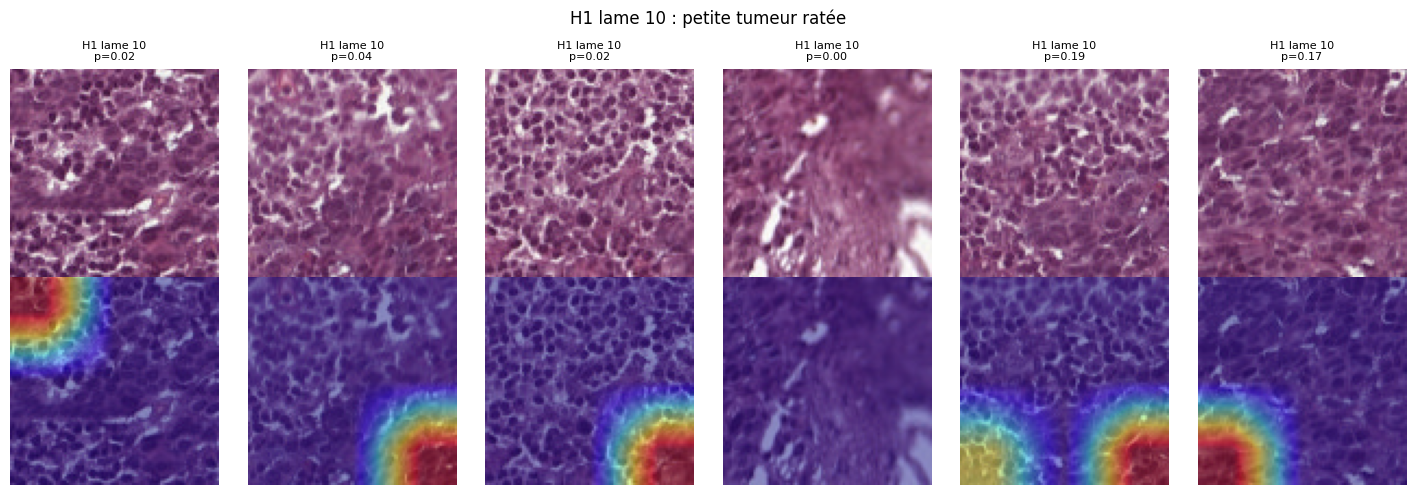

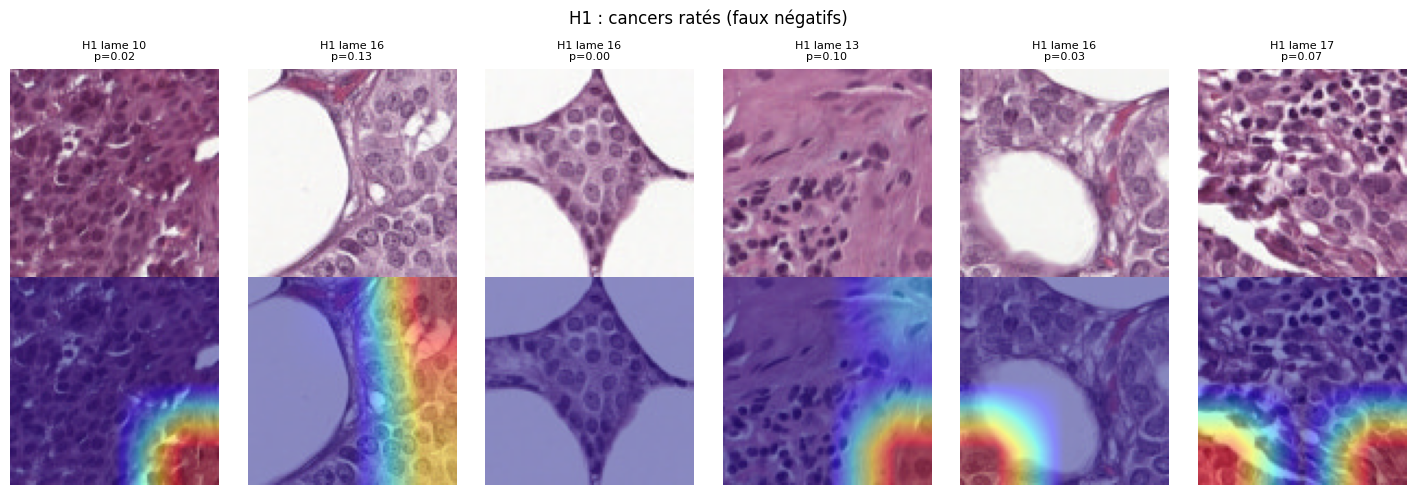

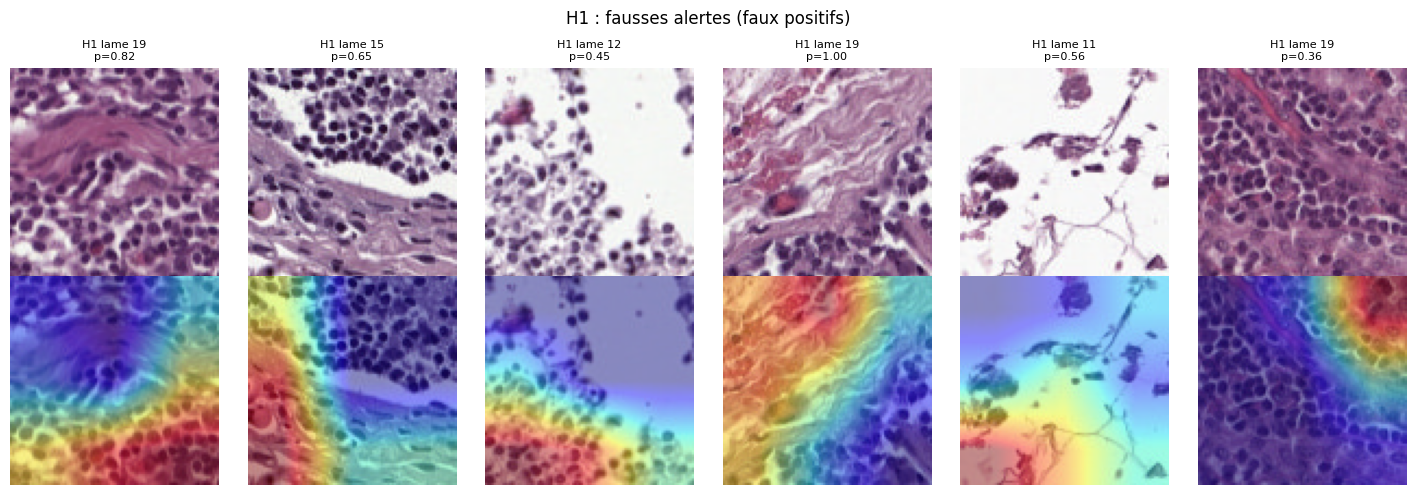

In [11]:
import matplotlib.pyplot as plt
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, couche):
        self.act = self.grad = None
        def accroche(m, i, o):
            self.act = o
            o.register_hook(lambda g: setattr(self, 'grad', g))
        couche.register_forward_hook(accroche)
    def __call__(self, x, classe=1):
        model.zero_grad()
        sortie = model(x)
        sortie[:, classe].sum().backward()
        poids = self.grad.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((poids * self.act).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), torch.softmax(sortie, 1)[0, 1].item()

gradcam = GradCAM(model, model.layer4[-1])

def montrer(sous_df, titre, n=6, fichier=None):
    sous_df = sous_df.sample(min(n, len(sous_df)), random_state=0)
    if len(sous_df) == 0: print('Aucun exemple pour', titre); return
    fig, ax = plt.subplots(2, len(sous_df), figsize=(2.4 * len(sous_df), 5), squeeze=False)
    for j, (_, r) in enumerate(sous_df.iterrows()):
        img = vers_pil(r[COL_IMG])
        cam, p = gradcam(TRANSFORM(img).unsqueeze(0).to(device))
        ax[0, j].imshow(img); ax[0, j].set_title(f"H{r['center']} lame {r['slide']}\np={p:.2f}", fontsize=8)
        ax[1, j].imshow(img); ax[1, j].imshow(cam, cmap='jet', alpha=0.45)
        for a in ax[:, j]: a.axis('off')
    fig.suptitle(titre); plt.tight_layout()
    if fichier: plt.savefig(DOSSIER + '/' + fichier, dpi=150, bbox_inches='tight')
    plt.show()

# Lignes H2 exécutées le 24/11 (figures enregistrées dans P5/resultats) ; désactivées le 25/11 pour ne pas recharger H2.
#montrer(h2[(h2['label'] == 1) & (h2['pred'] == 1)], 'H2 : cancers bien détectés', fichier='gradcam_H2_vrais_positifs.png')
#montrer(h2[(h2['label'] == 1) & (h2['pred'] == 0)], 'H2 : cancers RATÉS (faux négatifs)', fichier='gradcam_H2_faux_negatifs.png')
#montrer(h2[(h2['label'] == 0) & (h2['pred'] == 1)], 'H2 : fausses alertes', fichier='gradcam_H2_faux_positifs.png')

h1['pred'] = (h1['proba'] >= SEUIL).astype(int)
montrer(h1[(h1['slide'] == 10) & (h1['label'] == 1) & (h1['pred'] == 0)], 'H1 lame 10 : petite tumeur ratée', fichier='gradcam_H1_lame10.png')
montrer(h1[(h1['label'] == 1) & (h1['pred'] == 0)], 'H1 : cancers ratés (faux négatifs)', fichier='gradcam_H1_faux_negatifs.png')
montrer(h1[(h1['label'] == 0) & (h1['pred'] == 1)], 'H1 : fausses alertes (faux positifs)', fichier='gradcam_H1_faux_positifs.png')

In [ ]:
!find -L /content/drive/MyDrive -maxdepth 4 \( -name "best_model.pth" -o -name "predictions_resnet.csv" \) 2>/dev/null
!ls /content/drive/MyDrive/SPE1

/content/drive/MyDrive/SPE1/best_model.pth
/content/drive/MyDrive/SPE1/predictions_resnet.csv
01_baseline_ml.ipynb	 camelyon17_sous_echantillon.parquet
01_baseline_ml_v2.ipynb  predictions_resnet.csv
best_model.pth		 resultats_P2
